# Day 3: Cost Function and Convexity
**Implementing the Cost Function and Visualizing the Error Surface**

![Domain](https://img.shields.io/badge/Domain-Machine_Learning-blue)
![Status](https://img.shields.io/badge/Status-Completed-success)

> *Disclaimer: This notebook demonstrates the mathematical foundations of the cost function in univariate linear regression. Inspired by industry-standard resources like Andrew Ng's Coursera Specialization.*

---

## 1. The Cost Function (Mean Squared Error)
To find the optimal parameters $w$ and $b$, we need a mathematical way to measure how well our model's predictions match the actual training data. We use the squared error cost function:

$$J(w,b)=\frac{1}{2m}\sum_{i=0}^{m-1}(f_{w,b}(x^{(i)})-y^{(i)})^{2}$$

Where our prediction $f_{w,b}(x^{(i)})$ is given by the linear model:
$$f_{w,b}(x^{(i)})=wx^{(i)}+b$$

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def compute_cost(x, y, w, b):
    """
    Computes the cost function for linear regression.
    
    Args:
      x (ndarray (m,)): Data, m examples
      y (ndarray (m,)): Target values
      w, b (scalar)   : Model parameters
      
    Returns
      total_cost (float): The cost of using w, b as the parameters
    """
    m = x.shape[0] 
    cost_sum = 0
    
    for i in range(m):
        f_wb = w * x[i] + b 
        cost = (f_wb - y[i]) ** 2 
        cost_sum = cost_sum + cost
        
    total_cost = (1 / (2 * m)) * cost_sum
    return total_cost

## 2. Testing with a Larger Dataset
Real-world data rarely falls on a perfect straight line. Let's introduce a larger, more realistic dataset containing housing sizes and their corresponding prices.

In [4]:
# x_train_large: Size of the house (in 1000 square feet)
# y_train_large: Price of the house (in 1000s of dollars)
x_train_large = np.array([1.0, 1.7, 2.0, 2.5, 3.0, 3.2])
y_train_large = np.array([250.0, 300.0, 480.0, 430.0, 630.0, 730.0])

# Let's test with approximate optimal parameters derived from the gradient
w_optimal = 209.0 
b_optimal = 2.4  

cost = compute_cost(x_train_large, y_train_large, w_optimal, b_optimal)
print(f"Cost with w={w_optimal} and b={b_optimal}: {cost:.2f}")
# Note: Because the training examples are not perfectly linear, the minimum cost will be greater than zero.

Cost with w=209.0 and b=2.4: 1736.27


## 3. Convex Cost Surface & Visualization
Because our cost function squares the error (loss), it guarantees that the "error surface" is strictly **convex** (shaped like a soup bowl.)

This mathematical property ensures that our algorithm will always have a single **Global Minimum** that can be reached by following the gradient in all dimensions.

Let's visualize how our optimal regression line fits the scattered housing data.

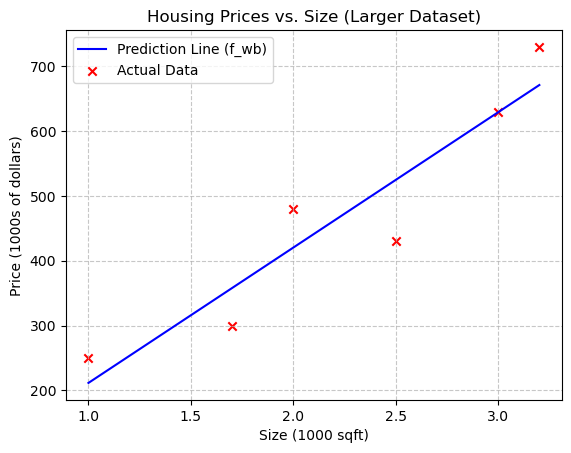

In [5]:
# Generate predictions using our approximate optimal parameters
predictions = w_optimal * x_train_large + b_optimal

# Plot the model's predictions (The regression line)
plt.plot(x_train_large, predictions, c='blue', label='Prediction Line (f_wb)')

# Plot the actual data points (The scatter crosses)
plt.scatter(x_train_large, y_train_large, marker='x', c='red', label='Actual Data')

# Set titles and labels
plt.title("Housing Prices vs. Size (Larger Dataset)")
plt.ylabel('Price (1000s of dollars)')
plt.xlabel('Size (1000 sqft)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()